# Linear Bimodal Momentum — demo

Self-contained demo of the linear variant of `py/apollo3/models/bimodal_momentum.py`
(Han & Qin 2026, *Bimodality Everywhere*), with an explicit **L2 (ridge) penalty**.

1. Bucket forward returns into K deciles **per date**.
2. Fit an L2-penalised multinomial logit `P(decile k | x)` — a free softmax, so the
   predicted distribution may put mass on *both* tails (bimodal).
3. Collapse probabilities to a score: `ret` = Σ_k P_k·μ_k (Eq. 12), `srp` = μ/σ (Eq. 14),
   vs the naive `argmax` = P(top) − P(bottom).

Data is synthetic: past winners drift up but carry crash risk, so their forward returns are bimodal.

In [1]:
import sys
from pathlib import Path

ROOT = next(p.resolve() for p in [Path.cwd(), *Path.cwd().parents] if (p / 'py' / 'apollo3').exists())
if str(ROOT / 'py') not in sys.path:
    sys.path.insert(0, str(ROOT / 'py'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, Ridge


%matplotlib inline

## Model

In [2]:
def cross_section_decile(returns, dates, K=10):
    """Per-date zero-based return bucket: 0 = lowest, K-1 = highest; -1 where missing.

    Bucket = ceil(rank * K / n) - 1 within each date, ties broken by row order
    (same rule as apollo3.math.bucketize_cross_section_zero_based).
    """
    r = pd.Series(np.asarray(returns, dtype=float))
    r = r.where(np.isfinite(r))
    g = r.groupby(np.asarray(dates))
    bucket = np.ceil(g.rank(method='first') * K / g.transform('count'))
    return bucket.fillna(0).astype(int).to_numpy() - 1


assert cross_section_decile([3, 1, 2, np.nan, 5, 4], [0, 0, 0, 0, 1, 1], K=3).tolist() == [2, 0, 1, -1, 2, 1]


class RidgeBimodalMomentum:
    """Linear Bimodal Momentum: L2-penalised multinomial logit over per-date return deciles.

    ``ridge_frac`` sets the L2 penalty as a fraction of training rows:
    alpha = ridge_frac * n, i.e. sklearn's C = 1 / alpha (sklearn sums the loss
    over rows, so a fixed C would weaken relative to the data as n grows).
    The caller must standardise X: the penalty assumes features on comparable scales.
    """

    def __init__(self, K=10, ridge_frac=0.02):
        self.K = K
        self.ridge_frac = ridge_frac

    def fit(self, X, fwd_ret):
        r = fwd_ret.reindex(X.index).to_numpy(dtype=float)
        y = cross_section_decile(pd.Series(r), X.index.get_level_values('date'), self.K)
        ok = (y >= 0) & np.isfinite(r)
        X, r, y = X[ok], r[ok], y[ok]
        self.mu_ = np.array([r[y == k].mean() for k in range(self.K)])
        self.sd_ = np.array([r[y == k].std() for k in range(self.K)])
        self.C_ = 1.0 / (self.ridge_frac * len(y))
        self.clf_ = LogisticRegression(C=self.C_, l1_ratio=0.0, max_iter=1000).fit(X, y)  # l1_ratio=0 -> pure L2
        return self

    def predict_proba(self, X):
        return pd.DataFrame(self.clf_.predict_proba(X), index=X.index, columns=range(self.K))

    def predict(self, X, method='ret'):
        """Per-row ranking score (higher = more winner-like): argmax, ret (Eq. 12) or srp (Eq. 14)."""
        P = self.predict_proba(X).to_numpy()
        if method == 'argmax':
            s = P[:, -1] - P[:, 0]
        elif method == 'ret':
            s = P @ self.mu_
        elif method == 'srp':
            mu = P @ self.mu_
            var = P @ (self.sd_**2 + self.mu_**2) - mu**2  # law of total variance
            s = mu / np.sqrt(np.clip(var, 1e-12, None))
        else:
            raise ValueError(method)
        return pd.Series(s, index=X.index)

## Synthetic panel

`mom ~ N(0,1)`. Forward return = `1%·mom` drift + noise, minus a −15% crash with probability
rising steeply in `mom`. Expected return is hump-shaped in `mom`: extreme winners have the
highest P(top decile) *and* a fat crash tail. Features are `mom` and `mom²` (feature engineering
is the caller's job; a linear logit needs `mom²` to see the tails).

train 56,000 rows, test 24,000 rows, split 2021-01-27


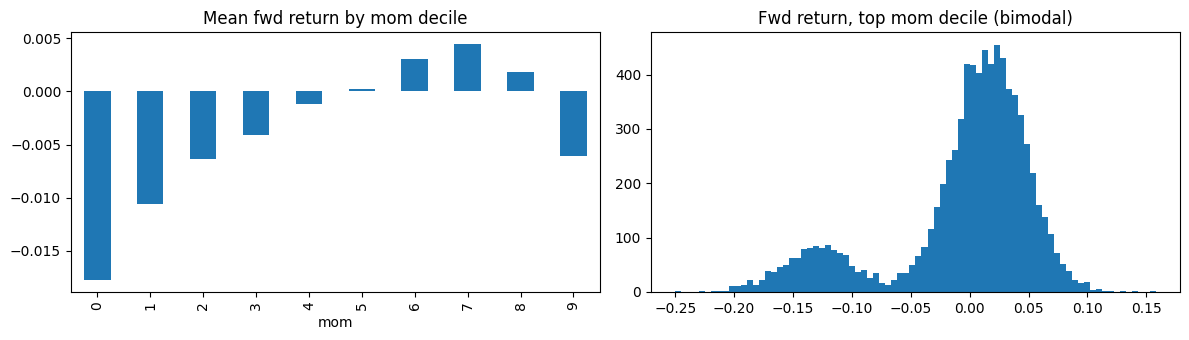

In [3]:
rng = np.random.default_rng(0)
n_dates, n_secs = 400, 200
idx = pd.MultiIndex.from_product(
    [pd.bdate_range('2020-01-01', periods=n_dates), [f's{i:03d}' for i in range(n_secs)]],
    names=['date', 'secId'])
mom = rng.normal(size=len(idx))
p_crash = 0.25 / (1 + np.exp(-3 * (mom - 1.5)))
fwd = pd.Series(0.01 * mom + rng.normal(0, 0.03, len(idx)) - 0.15 * (rng.random(len(idx)) < p_crash),
                index=idx, name='fwd_ret')
raw = pd.DataFrame({'mom': mom, 'mom2': mom**2}, index=idx)

dates = idx.get_level_values('date')
split = dates.unique()[int(0.7 * n_dates)]
tr, te = dates < split, dates >= split

# Standardise with training-period stats (the model expects scaled inputs)
x_mean, x_std = raw[tr].mean(), raw[tr].std()
X = (raw - x_mean) / x_std
print(f'train {tr.sum():,} rows, test {te.sum():,} rows, split {split.date()}')

bins = pd.qcut(raw['mom'], 10, labels=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
fwd.groupby(bins).mean().plot.bar(ax=ax[0], title='Mean fwd return by mom decile')
ax[1].hist(fwd[bins == 9], bins=80)
ax[1].set_title('Fwd return, top mom decile (bimodal)')
plt.tight_layout()

## Fit and inspect predicted class distributions

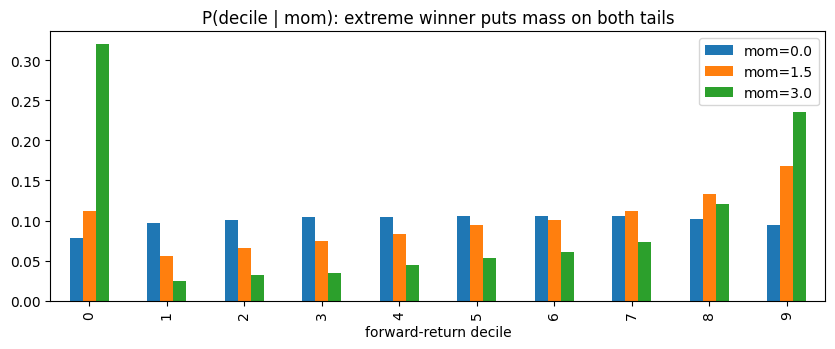

In [4]:
model = RidgeBimodalMomentum(K=10, ridge_frac=0.02).fit(X[tr], fwd[tr])

probe = pd.DataFrame({'mom': [0.0, 1.5, 3.0]})
probe['mom2'] = probe['mom']**2
P = pd.DataFrame(model.clf_.predict_proba((probe - x_mean) / x_std), index=[f'mom={m}' for m in probe['mom']])
P.T.plot.bar(figsize=(10, 3.5), title='P(decile | mom): extreme winner puts mass on both tails')
plt.xlabel('forward-return decile');

## Out-of-sample comparison

Per-date Spearman IC and top-minus-bottom decile spread on the test period. `ridge_reg` is plain
`Ridge` regression of returns on the same features (same 2%-of-rows alpha) — the direct-regression linear baseline.

In [5]:
def evaluate(score):
    df = pd.DataFrame({'s': score, 'r': fwd[te]})
    by_date = df.groupby(level='date')
    ic = by_date.apply(lambda g: g['s'].corr(g['r'], method='spearman'))
    dec = by_date['s'].transform(lambda s: pd.qcut(s.rank(method='first'), 10, labels=False))
    spread = df[dec == 9].groupby(level='date')['r'].mean() - df[dec == 0].groupby(level='date')['r'].mean()
    return pd.Series({'mean_IC': ic.mean(), 'IC_tstat': ic.mean() / ic.std() * np.sqrt(len(ic)),
                      'spread_mean': spread.mean(), 'spread_tstat': spread.mean() / spread.std() * np.sqrt(len(spread))})

scores = {m: model.predict(X[te], m) for m in ('argmax', 'ret', 'srp')}
ridge = Ridge(alpha=0.02 * tr.sum()).fit(X[tr], fwd[tr])
scores['ridge_reg'] = pd.Series(ridge.predict(X[te]), index=X[te].index)
scores['raw_mom'] = X.loc[te, 'mom']
pd.DataFrame({k: evaluate(v) for k, v in scores.items()}).T.round(4)

,mean_IC,IC_tstat,spread_mean,spread_tstat
argmax,0.2159,30.9713,0.0150,10.9833
ret,0.2170,31.0748,0.0155,11.4464
srp,0.2175,31.2420,0.0152,11.1415
ridge_reg,0.2025,31.5646,0.0228,20.1272
raw_mom,0.2178,31.7143,0.0126,9.4951


## L2 strength as a fraction of rows

Check the scaling: duplicating every training row must leave the coefficients unchanged,
because alpha doubles with n.

In [6]:
Xs, fs = X[tr].iloc[:5000], fwd[tr].iloc[:5000]
dup = lambda d: pd.concat([d, d.rename(index=lambda s: s + '_dup', level='secId')])
c1 = RidgeBimodalMomentum(ridge_frac=0.02).fit(Xs, fs).clf_.coef_
c2 = RidgeBimodalMomentum(ridge_frac=0.02).fit(dup(Xs), dup(fs)).clf_.coef_
assert np.allclose(c1, c2, atol=1e-4), np.abs(c1 - c2).max()
print('coef invariant to n: max diff', np.abs(c1 - c2).max())

coef invariant to n: max diff 3.3306690738754696e-16


`ridge_frac` sweep.

**Scaling effect — `ridge_frac` does not mean the same thing for both models.**
- *Ridge regression* on standardised features: each row adds 1 unit of curvature per direction
  (X'X ≈ n·I), so alpha = f·n shrinks each coefficient by ≈ 1/(1+f). f = 0.02 → ~2% shrink.
- *Multinomial logit*: each row adds only p(1−p) of curvature (Fisher information), with
  p ≈ 1/K. At K=10 that is ≈ 0.09, so the same f shrinks roughly **10x harder**:
  f = 0.02 → ~20% shrink (coef norm 0.94 → 0.75 below).
- For ~2% shrink in the logit, use `ridge_frac ≈ 0.02 · p(1−p) ≈ 0.002`. The factor grows with K.

In [7]:
rows = {}
for f in [1e-4, 1e-3, 1e-2, 0.02, 0.1, 1.0]:
    m = RidgeBimodalMomentum(K=10, ridge_frac=f).fit(X[tr], fwd[tr])
    coef_norm = np.linalg.norm(m.clf_.coef_)
    rows[f] = {'coef_L2_norm': coef_norm, **evaluate(m.predict(X[te], 'ret'))}
pd.DataFrame(rows).T.rename_axis('ridge_frac').round(4)

,coef_L2_norm,mean_IC,IC_tstat,spread_mean,spread_tstat
ridge_frac,,,,,
0.0001,0.9419,0.2167,31.0765,0.0153,11.1784
0.0010,0.9300,0.2167,31.0867,0.0154,11.3784
0.0100,0.8313,0.2168,31.0910,0.0153,11.2847
0.0200,0.7507,0.2170,31.0748,0.0155,11.4464
0.1000,0.4435,0.2173,31.1562,0.0155,11.3475
1.0000,0.0824,0.2177,31.3084,0.0148,10.9095
